<a href="https://colab.research.google.com/github/diseasemodeling/MIE_525_625/blob/main/Lectures/6c_PINN_ModelDiscovery_Batching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PROBLEM SETTING (EPIDEMIC EXAMPLE- S,I,R model)

$$[y_1, y_2, y_3]=[S,I,R]$$
  $$\frac{dS}{dt} = (-\beta  S  I)$$
  $$ \frac{dI}{dt} = (\beta  S  I - \gamma  I)$$
  $$ \frac{dR}{dt} = (\gamma  I)$$

  We assume **we do not know**
  - $\beta$
  - functional form of $\frac{dR}{dt}$
  - we know the initial conditions, any boundary conditions, and historical $x$ data

### OBJECTIVE
- Use PINN to learn blackbox function of $dy_3/dt$ and value of $\beta$, and
- Use PySR to learn functional form of $dy_3/dt$

# **Physics-Informed Neural Network (PINN) + PySR**
Same as 1b. Except
- We batch data for learning (notice we do not take consecutive time-steps in a batch, as PINN do not consider time-dependency, it treats each data point as an independent sample. We will look at time-series models later)
- Use PySR to discover unknown equations


# INVERSE PROBLEM:  Same as 6b
* using a few sampled data points
  - Solve for S, I, R,
  - solve for $\beta$

* NN architecture:    
    Net 1:     $$t --> NN1--> [S,I,R]$$
    Net 2 ($f$ represents learning $\frac{dR}{dT}$): $$[S,I,R, t] --> NN2-->f$$
    
    
* Foward pass:
    $$t -->NN1 --> [S,I,R]$$
    $$[S,I,R, t] --> NN2-->\frac{dR}{dt}$$
    $$ \beta \text{ is set as trainable scalar}$$

# Physics residuals  and Loss
    beta = epi_pinn.beta0 #get from learned NN
    f = pred_unknown_f #get from learned NN
    f_S = dS_dt - (-beta * S_p * I_p)
    f_I = dI_dt - (beta * S_p * I_p - gamma * I_p)
    f_R = dR_dt - f
    loss_physics = torch.mean(f_S**2) + torch.mean(f_I**2) + torch.mean(f_R**2)

# Model discovery

Find functional form of $\frac{dR}{dt}$
Use Symbolic Regression : https://pypi.org/project/pysr/0.3.13/
It typically uses, genetic algorithms (an optimizer), a type of nuemrical optimizaion method , to find analytical expressions that give a good fit to the data. The paramters you input to PySR correspond to paramters needed for the GA optimizer, including loss function, iterations.

    default_pysr_params = dict(
        populations=30,
        model_selection="score",
        #loss="L1DistLoss()",
        elementwise_loss="loss(prediction, target) = (prediction - target)^2"
    )
    # Learn equations

    # Learn equations
    model = PySRRegressor(
        niterations=30,
        # We can specify what binary operators and unary operators are allowed
        #binary_operators=["+", "*"],
        #unary_operators=["cos", "exp", "sin"],
        **default_pysr_params,
    )
    model.fit(X, y) # y are outputs from PINN

In [1]:
!pip install torchdiffeq

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torchdiffeq import odeint # Used only to generate true comparison data
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from scipy.integrate import solve_ivp

Setup Y-Net training. Input layer is 't' output layer are the states 'y'. NUmber in outlayer should match with number of state variables

In [3]:
# ── Y-Net: maps t → [y1, y2, y3] ────────────────────────────────────────
class YNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 50), nn.Tanh(),
            nn.Linear(50, 50), nn.Tanh(),
            nn.Linear(50, 3),
        )

    def forward(self, t):
        return self.net(t)

f_net takes 'y'(states) and 't' (time) in input layer and outputs $\dot{y}$ of the unknown function  ($\dot{x_3}$ in our case).

In [4]:
# ── F-Net: maps [t, y1, y2. y3] → scalar f  (behavioral response) ───────
class FNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 50), nn.Tanh(),
            nn.Linear(50, 50), nn.Tanh(),
            nn.Linear(50, 1),
        )

    def forward(self, t, y):
        inp = torch.cat([t, y], dim=1)
        return self.net(inp)

Put it together in PINN. Add the uknown coefficients to the output using the parameter layer, so it can part of the parameters to train.

In [5]:
# ── Full PINN ─────────────────────────────────────────────────────────────────
class EpiNet(nn.Module):
    def __init__(self, beta0_init: float = 0.1):
        super().__init__()
        self.y_net = YNet()
        self.f_net = FNet()
        # Learnable scalar β₀
        self.beta0 = nn.Parameter(torch.tensor([beta0_init], dtype=torch.float32))

    def forward(self, t):
        y = self.y_net(t)
        f = self.f_net(t, y)
        return y, f

# Generate true data (or upload true data)

In [6]:
# Setup known epidemic constants and true data for comparison
gamma =  0.1 # In this example, we assume we know these parameters- which are the coefficients in the ODEs.

# ── ODE simulation (ground truth) ────────────────────────────────────────────
def simulate_ODEs(y_init, t_span, obs_num):
    def odes(t, y):
        beta =0.3
        S, I, R = y[0], y[1], y[2]
        return [-beta*S*I, beta*S*I - gamma*I, gamma*I]

    # Solve ODEs using RK45 (for u_obs)
    t_eval = np.linspace(t_span[0], t_span[1], obs_num)
    sol = solve_ivp(odes, t_span, y_init, method="RK45", t_eval=t_eval)
    return np.column_stack((sol.t, sol.y[0], sol.y[1], sol.y[2]))

# Set up simulation
initial_state = [0.99, 0.01, 0.0]
t_span = [0, 50]
obs_num = 100

#Solve ODES
y_obs = simulate_ODEs(initial_state, t_span, obs_num)

In [7]:
# Collocation points for ODE loss
N_collocation = 10000
ODE_batch_size = 1000
X_train_ODE = torch.linspace(t_span[0], t_span[1], N_collocation).unsqueeze(1)
ode_dataset = TensorDataset(X_train_ODE)
ode_loader = DataLoader(ode_dataset, batch_size=ODE_batch_size, shuffle=True)

# Observed data for data loss
data_batch_size = 10
X_train_data = torch.tensor(y_obs[:, :1], dtype=torch.float32)
y_train_data = torch.tensor(y_obs[:, 1:], dtype=torch.float32)
data_dataset = TensorDataset(X_train_data, y_train_data)
data_loader = DataLoader(data_dataset, batch_size=data_batch_size, shuffle=True)

### PINN TRAIN

In [8]:
epi_pinn = EpiNet()
optimizer = optim.Adam(epi_pinn.parameters(), lr=0.001)

# Convert initial_state to a PyTorch tensor
initial_state = torch.tensor(initial_state, dtype=torch.float32)

In [9]:
epochs = 1500
for epoch in range(epochs):
    for (t_ODE,), (t, y) in zip(ode_loader, data_loader):
        optimizer.zero_grad()

        # -------------------------------------------------------------------------
        # 1. DATA LOSS (Comparing sparse model predictions against actual measurements)
        # -------------------------------------------------------------------------
        pred_y,_  = epi_pinn(t)
        loss_data = torch.mean((pred_y - y) ** 2)

        # -------------------------------------------------------------------------
        # 2. PHYSICS LOSS (Using a denser grid of collocation points to enforce laws)
        # -------------------------------------------------------------------------
        t_ODE.requires_grad_(True) # This line was added
        pred_phys, pred_unknown_f= epi_pinn(t_ODE)
        S_p, I_p, R_p = pred_phys[:, 0:1], pred_phys[:, 1:2], pred_phys[:, 2:3]

        # Compute derivatives from predicted values via autograd
        dS_dt = torch.autograd.grad(S_p, t_ODE, torch.ones_like(S_p), create_graph=True)[0]
        dI_dt = torch.autograd.grad(I_p, t_ODE, torch.ones_like(I_p), create_graph=True)[0]
        dR_dt = torch.autograd.grad(R_p, t_ODE, torch.ones_like(R_p), create_graph=True)[0]


        # Physics residuals (
        beta = epi_pinn.beta0 #get from learned NN
        f = pred_unknown_f #get from learned NN
        f_S = dS_dt - (-beta * S_p * I_p)
        f_I = dI_dt - (beta * S_p * I_p - gamma * I_p)
        f_R = dR_dt - f
        loss_physics = torch.mean(f_S**2) + torch.mean(f_I**2) + torch.mean(f_R**2)

        # -------------------------------------------------------------------------
        # 3. INITIAL CONDITION LOSS
        # -------------------------------------------------------------------------
        t_zero = torch.tensor([[0.0]])
        pred_zero, _ = epi_pinn(t_zero)
        loss_initial = torch.mean((pred_zero - initial_state)**2)

        # -------------------------------------------------------------------------
        # TOTAL LOSS: Balances observations + structural physics constraints
        # -------------------------------------------------------------------------
        total_loss = 1 * loss_data + 2.0 * loss_physics + 1 * loss_initial

        total_loss.backward()
        optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch} | Data Loss: {loss_data.item():.6f} | Physics Loss: {loss_physics.item():.6f}")

epi_pinn.eval()
with torch.no_grad():
        t_val = torch.linspace(t_span[0], t_span[1], 1000).unsqueeze(1)
        pred_y_PINN, _ = epi_pinn(t_val)



Epoch 0 | Data Loss: 0.044963 | Physics Loss: 0.005779
Epoch 500 | Data Loss: 0.000103 | Physics Loss: 0.000010
Epoch 1000 | Data Loss: 0.000010 | Physics Loss: 0.000002


In [16]:
# Anything with requires_grad = true becomes part of the computation graph. Though we did not explicity state it above, by using torch, we are making the initial loss  part of the computation graph.
# Note: not all use of torch tensors automatically make requires_grad = true (e.g., X is a tensor but we don't differentiate it).

# We can check what paramters have requires_grad = true
# Network parameters
for name, param in epi_pinn.named_parameters():
    print(name, param.requires_grad)

# Inputs
print("X_tensor:", X_train_data.requires_grad)
print("loss_initial output:", loss_initial.requires_grad)
pred_zero, _ = epi_pinn(t_zero)
print("pred_initial", pred_zero.requires_grad)

beta0 True
y_net.net.0.weight True
y_net.net.0.bias True
y_net.net.2.weight True
y_net.net.2.bias True
y_net.net.4.weight True
y_net.net.4.bias True
f_net.net.0.weight True
f_net.net.0.bias True
f_net.net.2.weight True
f_net.net.2.bias True
f_net.net.4.weight True
f_net.net.4.bias True
X_tensor: False
loss_initial output: True
pred_initial True


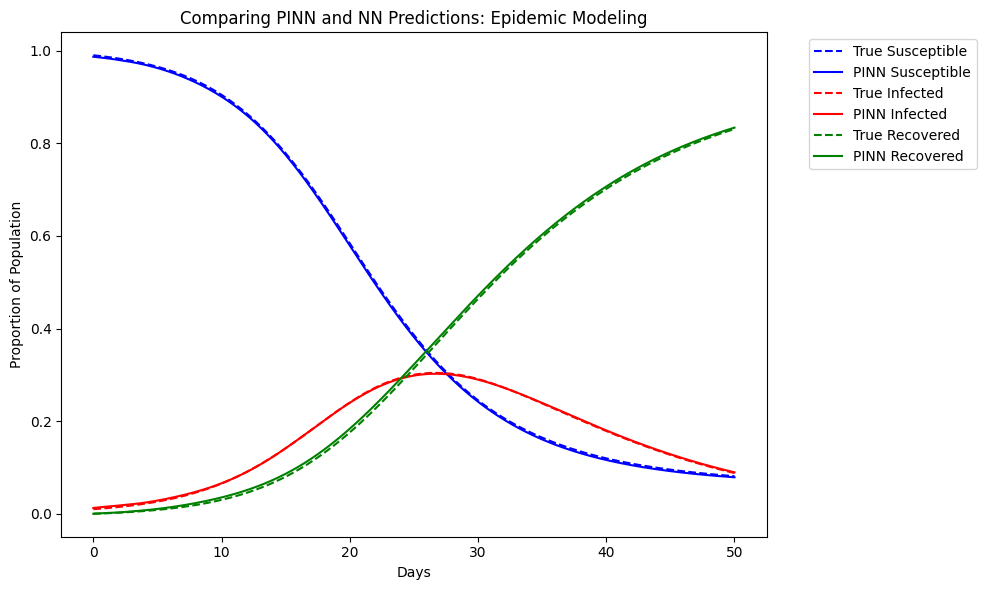

In [10]:
# Plot  Predictions vs Ground Truth
plt.figure(figsize=(10, 6))
labels = ['Susceptible', 'Infected', 'Recovered']
colors = ['blue', 'red', 'green']

for i in range(3):
    plt.plot(y_obs[:, 0], y_obs[:, i+1], label=f'True {labels[i]}', color=colors[i], linestyle='--')
    plt.plot(t_val.numpy(), pred_y_PINN[:, i].numpy(), label=f'PINN {labels[i]}', color=colors[i])

plt.title('Comparing PINN and NN Predictions: Epidemic Modeling')
plt.xlabel('Days')
plt.ylabel('Proportion of Population')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Discover equations using PySR

In [11]:
!pip install pysr

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 158.6/158.6 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.2/100.2 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 283.6/283.6 kB 18.4 MB/s eta 0:00:00
  Attempting uninstall: filelock
    Found existing installation: filelock 4.2.1
    Uninstalling filelock-4.2.1:
      Successfully uninstalled filelock-4.2.1


In [17]:
import sympy
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pysr import PySRRegressor
from sklearn.model_selection import train_test_split

/usr/local/lib/python3.13/dist-packages/juliacall/__init__.py:61: UserWarning: torch was imported before juliacall. This may cause a segfault. To avoid this, import juliacall before importing torch. For updates, see https://github.com/pytorch/pytorch/issues/78829.
  warnings.warn(


[juliapkg] Found dependencies: /usr/local/lib/python3.13/dist-packages/pysr/juliapkg.json
[juliapkg] Found dependencies: /usr/local/lib/python3.13/dist-packages/juliapkg/juliapkg.json
[juliapkg] Found dependencies: /usr/local/lib/python3.13/dist-packages/juliacall/juliapkg.json
[juliapkg] Locating Julia 1.10.3 - 1.11
[juliapkg] WARNING: You have Julia 1.12.6 installed but 1.10.3 - 1.11 is required.
[juliapkg]   It is recommended that you upgrade Julia or install JuliaUp.
[juliapkg] WARNING: About to install Julia 1.11.9 to /root/.julia/environments/pyjuliapkg/pyjuliapkg/install.
[juliapkg]   If you use juliapkg in more than one environment, you are likely to
[juliapkg]   have Julia installed in multiple locations. It is recommended to
[juliapkg]   install JuliaUp (https://github.com/JuliaLang/juliaup) or Julia
[juliapkg]   (https://julialang.org/downloads) yourself.
[juliapkg] Downloading Julia from https://julialang-s3.julialang.org/bin/linux/x64/1.11/julia-1.11.9-linux-x86_64.tar.gz


In [18]:
epi_pinn.eval()
with torch.no_grad():
        t_val = torch.linspace(t_span[0], t_span[1], 1000).reshape(-1, 1)
        pred_y_PINN, f = epi_pinn(t_val)
#print(t_val.numpy())
df = pd.DataFrame({
    't': t_val.numpy().flatten(),
    'x1': pred_y_PINN[:, 0].numpy(),
    'x2': pred_y_PINN[:, 1].numpy(),
    'x3': pred_y_PINN[:, 2].numpy(),
    'f': f.numpy().flatten(),
})

X = df.iloc[:, :4].to_numpy()
y = df.loc[:, 'f'].to_numpy()
print(df.iloc[:, :5].head)

<bound method NDFrame.head of              t        x1        x2        x3         f
0     0.000000  0.986769  0.012603  0.000036  0.004512
1     0.050050  0.986732  0.012689  0.000274  0.004055
2     0.100100  0.986623  0.012804  0.000444  0.003646
3     0.150150  0.986466  0.012943  0.000564  0.003282
4     0.200200  0.986278  0.013099  0.000652  0.002961
..         ...       ...       ...       ...       ...
995  49.799801  0.079229  0.090856  0.832029  0.009432
996  49.849850  0.079129  0.090521  0.832459  0.009392
997  49.899899  0.079029  0.090188  0.832888  0.009353
998  49.949951  0.078930  0.089856  0.833315  0.009313
999  50.000000  0.078831  0.089526  0.833741  0.009274

[1000 rows x 5 columns]>


In [19]:
default_pysr_params = dict(
    populations=30,
    model_selection="score",
    #loss="L1DistLoss()",
    elementwise_loss="loss(prediction, target) = (prediction - target)^2"
)


In [20]:
# Learn equations

# Learn equations
model = PySRRegressor(
    niterations=30,
    # We can specify what binary operators and unary operators are allowed
    #binary_operators=["+", "*"],
    #unary_operators=["cos", "exp", "sin"],
    **default_pysr_params,
)

model.fit(X, y)

Compiling Julia backend...
Compiling Julia backend...
INFO:pysr.sr:Compiling Julia backend...


PySRRegressor.equations_ = [
	   pick     score                                           equation  \
	0        0.000000                                         0.01781887   
	1  >>>>  2.536452                                    x2 * 0.10506409   
	2        0.749369                  0.0013227178 - (x2 * -0.09904644)   
	3        0.137517            (x2 * 0.10282056) + (x1 * 0.0013665227)   
	4        0.179415  0.0006050794 - ((x1 * -0.00086597266) + (x2 * ...   
	5        0.063564  (x2 + (x1 * 0.010937826)) * ((-0.018465733 * x...   
	6        0.007682  (x2 - (((x2 * (x2 * x2)) - x2) - ((x1 * x1) * ...   
	7        0.012646  (x2 - (((((x2 + x2) * (x2 * x2)) * x2) - x2) -...   
	8        0.036045  (x2 - (((x2 * ((((-0.0042419266 / x1) / x1) + ...   
	9        0.032689  (x2 - ((((((x2 * x2) + -0.006732714) * x3) * (...   
	
	           loss  complexity  
	0  8.713443e-05           1  
	1  5.458274e-07           3  
	2  1.219444e-07           5  
	3  9.262248e-08           7  
	4  6.469618e-08           9  
	5  5.697276e-08          11  
	6  5.440626e-08          17  
	7  5.172266e-08          21  
	8  4.812517e-08          23  
	9  4.507946e-08          25  
]

In [21]:
model.sympy()
print("Correct: x2*", gamma)
print("Discovered:", model.sympy())

Correct: x2* 0.1
Discovered: x2*0.10506409
